In [2]:
from typing import Annotated

from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [3]:
class State(TypedDict):
    messages: Annotated[list, add_messages]




In [ ]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

llm = ChatOpenAI(model="gpt-5-nano")

# response = llm.invoke("Hello! What is LangGraph?(be brief)")
# print(response.content)

LangGraph isn’t a single, widely known product. Generally, it could refer to a graph-based representation of language data (nodes as words/structures, edges as relations) or to a specific project by that name. If you have a link or more context, I can summarize it precisely.


In [5]:
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [6]:
graph_builder = StateGraph(State)

In [7]:
## Add Nodes
graph_builder.add_node("llmchatbot", chatbot)

## Add edges
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)


##complile the graph
graph = graph_builder.compile()


In [8]:
from IPython.display import Image, display

def display_graph(graph:StateGraph)->None:
    display(Image(graph.get_graph().draw_mermaid_png()))




In [9]:
for event in graph.stream({"messages": "what is langgraph"}):
    for value in event.values():
        print(value["messages"][-1].content)


I’m not sure which thing you’re referring to by “LangGraph.” There are a few possibilities:

- A specific project or library named LangGraph (in a particular language or ecosystem). If you have a link or more context (GitHub repo, language, or project page), I can summarize it.
- A general concept: a language-graph representation in NLP, where nodes represent language elements (words, lemmas, phrases, languages) and edges represent relationships (translations, syntactic dependencies, semantic relations, co-occurrence). This is used for parsing, multilingual knowledge graphs, translation, etc.
- A graph-based database or knowledge graph related to languages (linguistic data, cross-lingual links, dictionaries, corpora).

If you can share a link, a bit more context, or how you encountered it (documentation, code, a product page), I can give a precise definition and relevant details.


In [9]:
import os

## Chatbot with tools

In [10]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. [...] LangGraph illuminates the processes within an AI workflow, allowing full transparency of the agent’s state. Within LangGraph, the “state” feature serves as a memory bank that records and tracks all the valuable information processed by the AI system. It’s similar to a digital notebook where the system captures an

In [11]:
## custom function
def get_load_status(load_id: int) -> str:
    """
        Retrieve the current status of a trucking load using its unique ID.

        Args:
            load_id (int): The unique identifier of the trucking load.

        Returns:
            str: The current status of the load, such as "In transit",
                "Delivered", or "Pending pickup".
                Returns "Load not found" if the ID does not exist.
    """

    loads = {
        101: "In transit",
        102: "Delivered",
        103: "Pending pickup",
        104: "Delayed"
    }

    return loads.get(load_id, "Load not found")

In [12]:
import inspect
print(inspect.getdoc(get_load_status))

Retrieve the current status of a trucking load using its unique ID.

Args:
    load_id (int): The unique identifier of the trucking load.

Returns:
    str: The current status of the load, such as "In transit",
        "Delivered", or "Pending pickup".
        Returns "Load not found" if the ID does not exist.


In [13]:
tools = [tool, get_load_status]


In [14]:
llm_with_tools=llm.bind_tools(tools)

In [15]:
## Stategraph
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages":[response]}

## Graph
def basic_graph():
    builder = StateGraph(State)
    builder.add_node("tool_calling_llm",tool_calling_llm)
    builder.add_node("tools", ToolNode(tools))

    ## Add Edges
    builder.add_edge(START, "tool_calling_llm")
    builder.add_conditional_edges(
        "tool_calling_llm",
        tools_condition

    )

    builder.add_edge("tools", END)
    return builder

## compile

graph = basic_graph().compile()

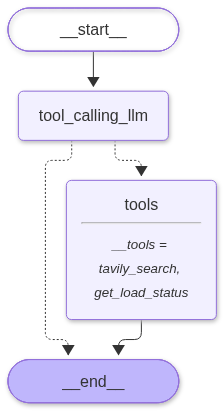

In [16]:
display_graph(graph)

In [17]:
import json
from pprint import pprint


In [50]:


prompts = [    """
    I'm a broker calling about trucking load 103.
    Can you check its current shipment status?
    """,

    # Test 2: Tavily web search tool
    """
    I'm a truck driver traveling from Houston to Dallas.
    Search the web for any major highway closures or
    construction on I-45 as of November 12, 2026.
    """,

    # Test 3: Internal load status tool (invalid ID)
    """
    Can you check the current status of load 999?
    """,

    # Test 4: Tavily web search tool
    """
    What is the latest average diesel fuel price
    per gallon in Texas? Search the web for current prices.
    """,
]

for i, prompt in enumerate(prompts, start=1):
    result = graph.invoke({
        "messages": [("user", prompt)]
    })

    print(f"\n--- Test {i} ---")

    for message in result["messages"]:
        if message.type == "ai" and message.tool_calls:
            for call in message.tool_calls:
                print("Tool selected:", call["name"])
                print("Arguments:")
                pprint(call["args"])

    print("\nOutput:")

    content = result["messages"][-1].content

    try:
        pprint(json.loads(content), sort_dicts=False)
    except (json.JSONDecodeError, TypeError):
        print(content)


--- Test 1 ---
Tool selected: get_load_status
Arguments:
{'load_id': 103}

Output:
Pending pickup

--- Test 2 ---
Tool selected: tavily_search
Arguments:
{'end_date': '2026-11-12',
 'query': 'I-45 closures construction Texas November 2026',
 'search_depth': 'advanced',
 'start_date': '2026-11-01'}

Output:
{'query': 'I-45 closures construction Texas November 2026',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://cw39.com/traffic/houston-i-45-road-closures',
              'title': 'I-45 improvement project holds public meetings next '
                       'week',
              'content': 'Updated: Nov 10, 2026 / 06:46 PM CST\n'
                         '\n'
                         'HOUSTON (CW39) – Two road closures near downtown '
                         'Houston have been extended through Nov. 30 as '
                         'construction continues, while TxDOT is inviting '
                         'residents and drivers to weigh in o

## ReAct Agent Architecture

In [18]:
def react_graph():
    builder = StateGraph(State)
    builder.add_node("tool_calling_llm",tool_calling_llm)
    builder.add_node("tools", ToolNode(tools))

    ## Add Edges
    builder.add_edge(START, "tool_calling_llm")
    builder.add_conditional_edges(
        "tool_calling_llm",
        tools_condition

    )
    builder.add_edge("tools","tool_calling_llm")

    builder.add_edge("tools", END)
    return builder

graph_one = react_graph().compile()

display_graph(react_graph)
    

AttributeError: 'function' object has no attribute 'get_graph'

In [19]:
prompt = """
I have a trucking load with ID 103.

First, use get_load_status to retrieve the current status of load 103.

Then, use Tavily to search the web for the latest average diesel
price per gallon in Texas.

Finally, report both the load status and the diesel price,
including the source for the diesel price.
"""

response = react_graph.invoke({
    "messages": [("user", prompt)]
})

for message in response["messages"]:
    message.pretty_print()

AttributeError: 'function' object has no attribute 'invoke'

## Adding Memory in Agentic Graph

In [21]:


response = graph.invoke({"messages":"Hello, my name is Sebastian"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hello, my name is Sebastian
================================== Ai Message ==================================

Hi Sebastian! Nice to meet you. How can I help you today? 

If you’d like, tell me what you’re working on or what you’re curious about. I can assist with writing, explanations, planning, coding, brainstorming, and more. And would you like me to call you Sebastian for our chat?


In [22]:
response = graph.invoke({"messages":"what is my name?"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is my name?
================================== Ai Message ==================================

I don’t know your name yet. You haven’t shared it with me. If you tell me what you’d like to be called, I’ll use that for this chat (and I can keep using it for the rest of this conversation). If you’d rather not share, I can just say “you” or use a nickname like “friend.”


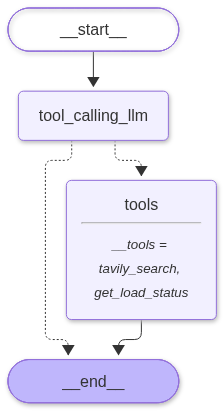

In [20]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

graph_builder = react_graph()

graph_two = graph_builder.compile(checkpointer=memory)

display_graph(graph)

In [ ]:
config={"configurable":{"thread_id":"1"}}

response = graph_two.invoke({"messages":"Hy myname is Sebastian"},config=config)
response['messages'][-1]

[HumanMessage(content='Hy myname is Sebastian', additional_kwargs={}, response_metadata={}, id='fc2a240b-b401-44bb-832d-808ea08d70b0'),
 AIMessage(content='Hi Sebastian! Nice to meet you. How can I help you today? If you’d like, I can tailor my responses to your interests—just tell me what you’re looking to do.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 432, 'prompt_tokens': 1311, 'total_tokens': 1743, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 384, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-nano-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EjdxH9HzINkUzdYhrpwPV108qHehF', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1d356-f5f3-75

In [29]:
response = graph_two.invoke({"messages":"What is my name?"}, config=config)

response["messages"][-1].content

'Your name is Sebastian — you told me that earlier. If you’d prefer a nickname, I can call you Seb or something else. How can I help you today?'

## Streaming

In [21]:
memory = MemorySaver()

In [22]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

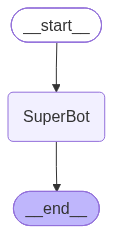

In [24]:
graph_builder=StateGraph(State)

graph_builder.add_node("SuperBot", superbot)

graph_builder.add_edge(START, "SuperBot")
graph_builder.add_edge("SuperBot", END)

graph=graph_builder.compile(checkpointer=memory)

display_graph(graph)

In [29]:
config = {"configurable":{"thread_id":"3"}}

for chunk in graph.stream({'messages':"Hi, my name is Sebastian and I like soccer"}, config, stream_mode="values"):
    print(chunk)


{'messages': [HumanMessage(content='Hi, my name is Sebastian and I like soccer', additional_kwargs={}, response_metadata={}, id='5b898ca8-061e-464b-88e6-0abb80ceeee0'), AIMessage(content='Nice to meet you, Sebastian! Soccer is awesome. Do you play yourself or mostly watch? Who’s your favorite team or player? What would you like to chat about—games, tactics, drills to improve, or latest soccer news? If you want, I can suggest a quick at-home training routine or position-specific drills to help you improve.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 655, 'prompt_tokens': 16, 'total_tokens': 671, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 576, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-

In [31]:
config = {"configurable":{"thread_id":"4"}}

for chunk in graph.stream({'messages':"Hi, my name is Sebastian and I like soccer"}, config, stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Nice to meet you again, Sebastian! Soccer is awesome. Since you’re into it, want me to tailor something for you or run through a quick plan? Here are a few easy options:\n\n- 15-minute home practice routine (no gear): warm-up, ball control, dribbling, passing/receiving, finishing.\n- Quick primer on a common formation (e.g., 4-3-3 or 4-2-3-1) and what each position does.\n- Drills to boost a specific area (touch, first touch, finishing, or speed with the ball).\n- Short game analysis—tips for your favorite position, or a small-sided drill you can use in training.\n\nA few questions to tailor it:\n- What position do you play, or which area do you want to improve most (touch, dribbling, shooting, fitness, tactics)?\n- What’s your current level (recreational, academy, high school/college)?\n- Do you have space at home or a nearby field, and any equipment (cones, wall, a ball)?\n\nIf you want, I can just give you a ready-to-run 15-minute routin

In [32]:
for chunk in graph.stream({'messages':"i also like programming"}, config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, my name is Sebastian and I like soccer', additional_kwargs={}, response_metadata={}, id='fd109193-5dcd-4c6f-8c5f-9a179353f2dc'), AIMessage(content='Hi Sebastian! Great to meet you—soccer is awesome. Do you play, watch, or both? What would you like to dive into—training tips, tactics, your favorite team or player, or the latest news? If you want, I can suggest a quick 15-minute practice routine, explain a formation, or break down some stats like expected goals. Tell me your level and what you’re aiming for.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 478, 'prompt_tokens': 16, 'total_tokens': 494, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 384, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model